# 01 · Backpropagation y autograd desde cero

**Objetivo:** ver que backpropagation es solo la regla de la cadena aplicada en orden inverso
sobre un grafo de cómputo, construir ese grafo con `applied_dl.Tensor` y comprobar que
coincide con PyTorch. Luego, usar el mismo motor para ver por qué las redes profundas
“olvidan” cómo aprender (gradientes que se desvanecen) y cómo lo arreglan la inicialización
y la ReLU.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from common import set_seed, setup_style

setup_style()
rng = set_seed(42)
import torch
from applied_dl import Tensor, cross_entropy
from applied_dl.nn import MLP

## 1. Un grafo pequeño, a mano

$L = (\tanh(w x + b) - y)^2$. Hacia adelante calculamos cada nodo; hacia atrás, cada derivada
local multiplicada por la que llega desde arriba.

In [2]:
x, y, w, b = 0.5, 0.8, 1.2, -0.3
z = w * x + b
h = np.tanh(z)
L = (h - y) ** 2
dL_dh = 2 * (h - y)
dh_dz = 1 - h**2
dL_dw, dL_db = dL_dh * dh_dz * x, dL_dh * dh_dz * 1
print(f"a mano:   dL/dw = {dL_dw:.6f}, dL/db = {dL_db:.6f}")

wt, bt = Tensor(w, requires_grad=True), Tensor(b, requires_grad=True)
((wt * x + bt).tanh() - y).__pow__(2).backward()
print(f"autograd: dL/dw = {wt.grad:.6f}, dL/db = {bt.grad:.6f}")

wr, br = torch.tensor(w, requires_grad=True), torch.tensor(b, requires_grad=True)
((torch.tanh(wr * x + br) - y) ** 2).backward()
print(f"torch:    dL/dw = {wr.grad.item():.6f}, dL/db = {br.grad.item():.6f}")

a mano:   dL/dw = -0.465519, dL/db = -0.931037
autograd: dL/dw = -0.465519, dL/db = -0.931037
torch:    dL/dw = -0.465519, dL/db = -0.931037


## 2. Por qué modo reverso

Una red con millones de parámetros y una pérdida escalar: el modo reverso obtiene **todos** los
gradientes con un solo recorrido hacia atrás, a un costo similar al del forward. El modo directo
necesitaría un recorrido por parámetro. Medimos el costo del backward frente al forward:

In [3]:
import time

Xd = rng.normal(size=(512, 256))
yd = rng.integers(0, 10, 512)
net = MLP([256, 512, 512, 10], rng=rng)
t0 = time.perf_counter()
for _ in range(20):
    loss = cross_entropy(net(Tensor(Xd)), yd)
t_fwd = (time.perf_counter() - t0) / 20
t0 = time.perf_counter()
for _ in range(20):
    net.zero_grad()
    cross_entropy(net(Tensor(Xd)), yd).backward()
t_both = (time.perf_counter() - t0) / 20
n_params = sum(p.data.size for p in net.parameters())
print(
    f"{n_params:,} parámetros | forward {t_fwd * 1e3:.1f} ms"
    f" | forward+backward {t_both * 1e3:.1f} ms ({t_both / t_fwd:.1f}× el forward)"
)

399,370 parámetros | forward 2.1 ms | forward+backward 5.3 ms (2.5× el forward)


## 3. Gradientes que se desvanecen (y explotan)

Red de 20 capas de ancho 128. Norma del gradiente de los pesos de cada capa tras un backward,
para tres combinaciones de activación e inicialización.

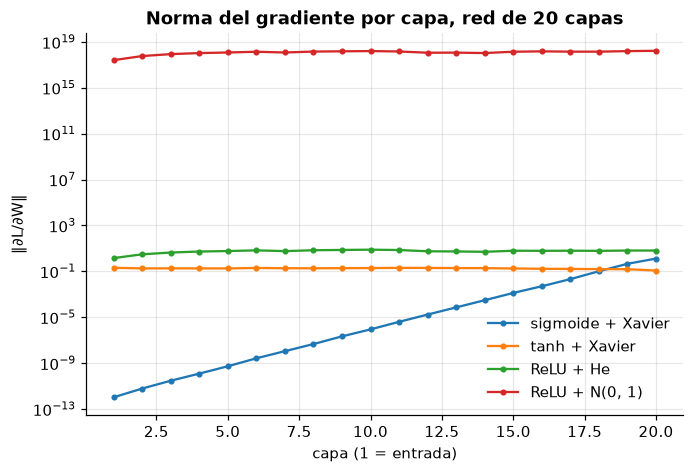

In [4]:
X = rng.normal(size=(256, 128))
y = rng.integers(0, 10, 256)
configs = {
    "sigmoide + Xavier": ("sigmoid", "xavier"),
    "tanh + Xavier": ("tanh", "xavier"),
    "ReLU + He": ("relu", "he"),
    "ReLU + N(0, 1)": ("relu", "naive"),
}
fig, ax = plt.subplots()
for label, (act, init) in configs.items():
    net = MLP([128] * 20 + [10], activation=act, init=init, rng=np.random.default_rng(0))
    cross_entropy(net(Tensor(X)), y).backward()
    norms = [np.linalg.norm(layer.W.grad) for layer in net.layers]
    ax.semilogy(range(1, len(norms) + 1), norms, "o-", ms=3, label=label)
ax.set_xlabel("capa (1 = entrada)")
ax.set_ylabel("‖∂L/∂W‖")
ax.set_title("Norma del gradiente por capa, red de 20 capas")
ax.legend();

- **Sigmoide**: su derivada es ≤ 0.25; multiplicada 20 veces, el gradiente de las primeras capas
  es órdenes de magnitud menor que el de las últimas. Esas capas casi no aprenden.
- **ReLU + He**: derivada 1 donde está activa y una varianza de pesos que compensa la mitad
  anulada: la norma se mantiene estable a lo largo de la red.
- **ReLU + N(0, 1)**: sin escalar por $1/\sqrt{\text{fan\_in}}$, las activaciones crecen ~$\sqrt{128}$
  veces por capa: gradientes que explotan.

## Para llevar

- Backprop = regla de la cadena + programación dinámica sobre el grafo (cada derivada local se usa una vez).
- El modo reverso cuesta un múltiplo pequeño del forward, sin importar el número de parámetros.
- Activación e inicialización deciden si una red profunda es entrenable antes de elegir el optimizador.